In [1]:
from pathlib import Path
import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
import xgboost
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

pd.set_option("display.max_columns", None)
print(f"scikit-learn: {sklearn.__version__}")
print(f"xgboost:       {xgboost.__version__}")
print(f"shap:          {shap.__version__}")


scikit-learn: 1.8.0
xgboost:       3.2.0
shap:          0.51.0


## Configuration

Set either training flag to `False` if only one tree model is needed. The PySR equation is already fitted and is evaluated directly. Saved artifacts are written under `outputs/best_models/`.

In [2]:
DATA_PATH = Path("Feynman_without_units/I.9.18_sample_10000")
OUTPUT_DIR = Path("outputs/best_models")

RANDOM_STATE = 42
TEST_SIZE = 0.20
TRAIN_RANDOM_FOREST = True
TRAIN_XGBOOST = True
SAVE_ARTIFACTS = True
NOISE_LEVELS = [0.0, 0.025, 0.05]
NOISE_REPEATS = 100
CONTINUITY_REPEATS = 20
CONTINUITY_SAMPLE_SIZE = 50
RESPONSE_STABILITY_FRACTION = 0.05

COLUMN_NAMES = [
    "m2_m1", "x2_x1", "y1_x1", "y2_x1", "z1_x1", "z2_x1", "target"
]
FEATURE_COLUMNS = COLUMN_NAMES[:-1]
FEATURE_LABELS = ["m2/m1", "x2/x1", "y1/x1", "y2/x1", "z1/x1", "z2/x1"]

RF_PARAMS = {
    "n_estimators": 277,
    "max_depth": 20,
    "max_features": 1.0,
    "min_samples_leaf": 1,
    "min_samples_split": 2,
}

XGB_PARAMS = {
    "n_estimators": 603,
    "max_depth": 4,
    "learning_rate": 0.1189,
    "subsample": 0.6407,
    "colsample_bytree": 0.6135,
    "min_child_weight": 13,
    "reg_alpha": 0.5058,
    "reg_lambda": 1.5675,
}

PYSR_RESULT = {
    "label": "ps200_p80_ni1000_par0.001_adp1000",
    "population_size": 200,
    "populations": 80,
    "niterations": 1000,
    "parsimony": 0.001,
    "adaptive_parsimony_scaling": 1000,
    "complexity": 17,
    "best_loss": 9.297229e-15,
    "test_mse": 4.918208780382796e-31,
    "r2": 1.0,
    "raw_equation": (
        "m2_m1 / ((square(y1_x1 - y2_x1) + "
        "square(x2_x1 - square(1.0))) + square(z2_x1 - z1_x1))"
    ),
    "simplified_equation": (
        "m2_m1 / ((x2_x1 - 1)**2 + (y2_x1 - y1_x1)**2 + "
        "(z2_x1 - z1_x1)**2)"
    ),
}

LOGGED_TEST_METRICS = pd.DataFrame(
    {
        "logged_test_mse": {
            "Random Forest": 0.006832,
            "XGBoost": 0.001126,
            "PySR": PYSR_RESULT["test_mse"],
        },
        "logged_test_r2": {
            "Random Forest": 0.955581,
            "XGBoost": 0.992676,
            "PySR": PYSR_RESULT["r2"],
        },
    }
)

print(f"Data: {DATA_PATH.resolve()}")
print(f"Output: {OUTPUT_DIR.resolve()}")

Data: C:\Users\jarra\OneDrive\Documents\Work\UWA\Year 4\Research Project\Project\Feynman_without_units\I.9.18_sample_10000
Output: C:\Users\jarra\OneDrive\Documents\Work\UWA\Year 4\Research Project\Project\outputs\best_models


**Raw PySR equation**

$$
\frac{\mathrm{m2\_m1}}
{
\left(\mathrm{y1\_x1}-\mathrm{y2\_x1}\right)^2
+
\left(\mathrm{x2\_x1}-1^2\right)^2
+
\left(\mathrm{z2\_x1}-\mathrm{z1\_x1}\right)^2
}
$$

**Simplified PySR equation**

$$
\frac{\mathrm{m2\_m1}}
{
\left(\mathrm{x2\_x1}-1\right)^2
+
\left(\mathrm{y2\_x1}-\mathrm{y1\_x1}\right)^2
+
\left(\mathrm{z2\_x1}-\mathrm{z1\_x1}\right)^2
}
$$

## Load and split the data

In [3]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Run this notebook from the project root or update DATA_PATH."
    )

data = pd.read_csv(
    DATA_PATH,
    sep=r"\s+",
    header=None,
    names=COLUMN_NAMES,
)

if data.shape[1] != len(COLUMN_NAMES):
    raise ValueError(f"Expected {len(COLUMN_NAMES)} columns, found {data.shape[1]}.")
if data.empty:
    raise ValueError("The dataset is empty.")
if not np.isfinite(data.to_numpy()).all():
    raise ValueError("The dataset contains missing or non-finite values.")

X = data[FEATURE_COLUMNS]
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

print(f"Dataset shape: {data.shape}")
print(f"Training set:  {X_train.shape}")
print(f"Test set:      {X_test.shape}")
display(data.head())
display(data.describe().T)

Dataset shape: (10000, 7)
Training set:  (8000, 6)
Test set:      (2000, 6)


,m2_m1,x2_x1,y1_x1,y2_x1,z1_x1,z2_x1,target
0,0.974949,0.362593,0.995257,0.464699,0.773166,0.338407,1.111946
1,1.252762,0.281120,0.855649,0.389632,0.978491,0.331575,1.087033
2,0.699618,0.318068,0.985414,0.340872,1.038457,0.351886,0.517527
3,0.701715,0.338213,0.869104,0.528031,0.847783,0.444075,0.978310
4,1.064502,0.357968,1.048368,0.391723,1.281532,0.464366,0.704433


,count,mean,std,min,25%,50%,75%,max
m2_m1,10000.0,1.033633,0.290825,0.504786,0.812379,0.994354,1.206208,1.999007
x2_x1,10000.0,0.430477,0.090648,0.252024,0.356433,0.428166,0.498432,0.663452
y1_x1,10000.0,1.007103,0.118203,0.752311,0.920560,1.001548,1.087132,1.331390
y2_x1,10000.0,0.431050,0.090535,0.252338,0.356643,0.429016,0.499559,0.662864
z1_x1,10000.0,1.006771,0.118430,0.752206,0.919212,0.999235,1.088057,1.328649
z2_x1,10000.0,0.432419,0.090030,0.251512,0.359172,0.431787,0.499415,0.661624
target,10000.0,1.060684,0.396058,0.303822,0.773988,0.988597,1.272783,3.806909


## Train the tuned tree models and load the symbolic model

The tree models are direct final fits, so the expensive randomized and grid searches are not repeated. The selected PySR result simplifies to the exact inverse-square expression and does not need retraining.

In [4]:
models_to_fit = {}

if TRAIN_RANDOM_FOREST:
    models_to_fit["Random Forest"] = RandomForestRegressor(
        **RF_PARAMS,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        oob_score=True,
    )

if TRAIN_XGBOOST:
    models_to_fit["XGBoost"] = XGBRegressor(
        **XGB_PARAMS,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0,
    )

if not models_to_fit:
    raise ValueError("Enable at least one model in the configuration cell.")

models = {}
fit_seconds = {}

for model_name, model in models_to_fit.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds[model_name] = time.perf_counter() - start
    models[model_name] = model
    print(f"{model_name} fitted in {fit_seconds[model_name]:.2f} seconds")


def predict_pysr(rows):
    denominator = (
        (rows["x2_x1"].to_numpy() - 1.0) ** 2
        + (rows["y2_x1"].to_numpy() - rows["y1_x1"].to_numpy()) ** 2
        + (rows["z2_x1"].to_numpy() - rows["z1_x1"].to_numpy()) ** 2
    )
    if np.any(denominator == 0):
        raise ZeroDivisionError("The PySR equation is undefined at zero separation.")
    return rows["m2_m1"].to_numpy() / denominator


print("Selected PySR configuration:", PYSR_RESULT["label"])
print("Simplified equation:", PYSR_RESULT["simplified_equation"])

Random Forest fitted in 3.83 seconds


XGBoost fitted in 1.64 seconds
Selected PySR configuration: ps200_p80_ni1000_par0.001_adp1000
Simplified equation: m2_m1 / ((x2_x1 - 1)**2 + (y2_x1 - y1_x1)**2 + (z2_x1 - z1_x1)**2)


## Analysis

### 1. Predictive performance

Following the predictive-performance comparison in Table 3 (p.16), the clean held-out test set is summarized with \(R^2\), RMSE, and MAE.


In [5]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_true, y_pred),
    }


predictions = {}
clean_rows = []

for model_name, model in models.items():
    test_pred = model.predict(X_test)
    predictions[model_name] = {"test": test_pred}
    clean_rows.append(
        {
            "Method": model_name,
            **regression_metrics(y_test, test_pred),
        }
    )

pysr_test_pred = predict_pysr(X_test)
predictions["PySR"] = {"test": pysr_test_pred}
clean_rows.append(
    {
        "Method": "PySR",
        **regression_metrics(y_test, pysr_test_pred),
    }
)

clean_performance = pd.DataFrame(clean_rows).set_index("Method")
metrics = clean_performance.copy()
display(clean_performance.round(6))


,R2,RMSE,MAE
Method,,,
Random Forest,0.955581,0.082653,0.056745
XGBoost,0.992921,0.032996,0.022097
PySR,1.000000,0.000000,0.000000


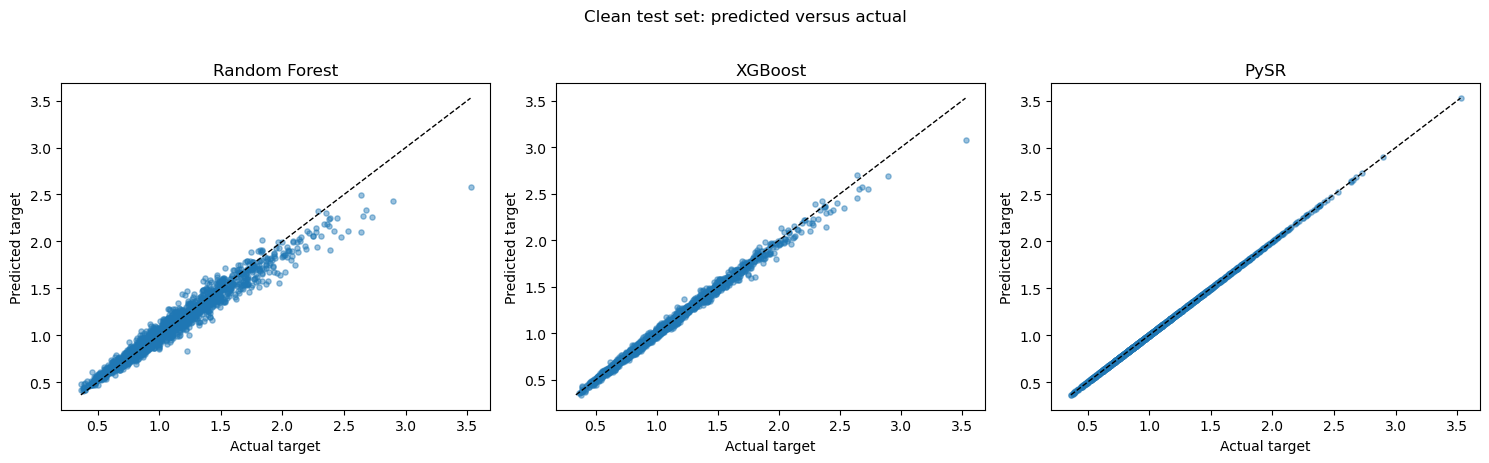

In [6]:
fig, axes = plt.subplots(1, len(predictions), figsize=(15, 4.5), squeeze=False)

for axis, (model_name, split_predictions) in zip(axes[0], predictions.items()):
    test_pred = split_predictions["test"]
    lower = min(y_test.min(), test_pred.min())
    upper = max(y_test.max(), test_pred.max())

    axis.scatter(y_test, test_pred, alpha=0.45, s=14)
    axis.plot([lower, upper], [lower, upper], "k--", linewidth=1)
    axis.set_title(model_name)
    axis.set_xlabel("Actual target")
    axis.set_ylabel("Predicted target")

fig.suptitle("Clean test set: predicted versus actual", y=1.02)
plt.tight_layout()
plt.show()


### 2. Controlled synthetic data check

The known Feynman equation is used as the reference explanation. For a simple oracle importance, each test feature is independently permuted while the other five are held fixed; importance is the resulting mean absolute change in the true equation, averaged over 10 seeded permutations.

TreeSHAP and equation recovery describe different kinds of explanations, so the tree-model ranking results and PySR structure are shown separately.


In [7]:
def shap_matrix(explainer, rows):
    values = explainer.shap_values(rows, check_additivity=False)
    if isinstance(values, list):
        if len(values) != 1:
            raise ValueError("Expected one SHAP output for scalar regression.")
        values = values[0]
    values = np.asarray(values)
    if values.ndim == 3 and values.shape[-1] == 1:
        values = values[..., 0]
    if values.ndim != 2:
        raise ValueError(f"Expected a 2D SHAP matrix, received {values.shape}.")
    return values


tree_explainers = {}
clean_shap_values = {}
mean_abs_shap = {}

for model_name, model in models.items():
    explainer = shap.TreeExplainer(model)
    values = shap_matrix(explainer, X_test)
    tree_explainers[model_name] = explainer
    clean_shap_values[model_name] = values
    mean_abs_shap[model_name] = np.mean(np.abs(values), axis=0)

ORACLE_REPEATS = 10
oracle_rng = np.random.default_rng(RANDOM_STATE)
true_test_output = predict_pysr(X_test)
oracle_importance = {}

for feature in FEATURE_COLUMNS:
    changes = []
    for _ in range(ORACLE_REPEATS):
        perturbed = X_test.copy()
        perturbed[feature] = oracle_rng.permutation(
            perturbed[feature].to_numpy()
        )
        changes.append(
            np.mean(np.abs(predict_pysr(perturbed) - true_test_output))
        )
    oracle_importance[feature] = np.mean(changes)

oracle_vector = np.array(
    [oracle_importance[feature] for feature in FEATURE_COLUMNS]
)
ranking_table = pd.DataFrame(
    {
        "Feature": FEATURE_LABELS,
        "Oracle importance": oracle_vector,
        "Oracle rank": pd.Series(oracle_vector).rank(
            method="min", ascending=False
        ).astype(int),
    }
)

alignment_rows = []
for model_name in models:
    shap_vector = mean_abs_shap[model_name]
    ranking_table[f"{model_name} mean |SHAP|"] = shap_vector
    ranking_table[f"{model_name} SHAP rank"] = pd.Series(shap_vector).rank(
        method="min", ascending=False
    ).astype(int)
    correlation = spearmanr(shap_vector, oracle_vector)[0]
    alignment_rows.append(
        {
            "Method": model_name,
            "Spearman correlation": correlation,
        }
    )

oracle_alignment = pd.DataFrame(alignment_rows).set_index("Method")
display(ranking_table.sort_values("Oracle rank").reset_index(drop=True).round(6))
display(oracle_alignment.round(3))


,Feature,Oracle importance,Oracle rank,Random Forest mean |SHAP|,Random Forest SHAP rank,XGBoost mean |SHAP|,XGBoost SHAP rank
0,m2/m1,0.327671,1,0.231123,1,0.233777,1
1,z1/x1,0.163436,2,0.084047,3,0.105661,3
2,y1/x1,0.159806,3,0.095522,2,0.107989,2
3,x2/x1,0.137255,4,0.077406,4,0.092639,4
4,y2/x1,0.127991,5,0.074058,5,0.088836,5
5,z2/x1,0.125322,6,0.070739,6,0.085522,6


,Spearman correlation
Method,
Random Forest,0.943
XGBoost,0.943


In [8]:
pysr_expression = PYSR_RESULT["simplified_equation"]
pysr_variables = [
    feature for feature in FEATURE_COLUMNS if feature in pysr_expression
]

print("Selected PySR expression:")
print(pysr_expression)
display(
    pd.DataFrame(
        {
            "Variables recovered": [f"{len(pysr_variables)} of 6"],
            "PySR complexity": [PYSR_RESULT["complexity"]]
        },
        index=["PySR"],
    )
)


Selected PySR expression:
m2_m1 / ((x2_x1 - 1)**2 + (y2_x1 - y1_x1)**2 + (z2_x1 - z1_x1)**2)


,Variables recovered,PySR complexity
PySR,6 of 6,17


### 3. Noise sensitivity

This follows the paper's Stability for Slight Variations method (pp.17, 23) and matches the stronger body-fat protocol. Gaussian noise is scaled by each feature's training-set standard deviation, with the same paired draws used across models and noise levels. Values are not clipped, avoiding abrupt projection onto observed boundaries. Predictive robustness is evaluated over 100 draws on all test rows; the more expensive TreeSHAP continuity calculation uses the first 20 non-zero draws on a fixed, seeded 50-row subset selected independently of model outputs. This closely matches the 51-row body-fat test-set scale. Explanation similarity is interpreted separately for rows whose prediction changes by no more than 5% of the training-target standard deviation.


In [9]:
def row_cosine_similarity(reference, comparison):
    reference = np.asarray(reference)
    comparison = np.asarray(comparison)
    dots = np.sum(reference * comparison, axis=1)
    reference_norm = np.linalg.norm(reference, axis=1)
    comparison_norm = np.linalg.norm(comparison, axis=1)
    denominators = reference_norm * comparison_norm

    similarities = np.zeros(reference.shape[0], dtype=float)
    nonzero = denominators > np.finfo(float).eps
    similarities[nonzero] = dots[nonzero] / denominators[nonzero]
    both_zero = (
        (reference_norm <= np.finfo(float).eps)
        & (comparison_norm <= np.finfo(float).eps)
    )
    similarities[both_zero] = 1.0
    return np.clip(similarities, -1.0, 1.0)


noise_rng = np.random.default_rng(RANDOM_STATE)
noise_draws = [
    noise_rng.normal(size=X_test.shape)
    for _ in range(NOISE_REPEATS)
]
train_std = X_train.std(axis=0, ddof=0).to_numpy()
response_stability_tolerance = (
    RESPONSE_STABILITY_FRACTION * y_train.std(ddof=0)
)
continuity_rng = np.random.default_rng(RANDOM_STATE)
continuity_positions = np.sort(
    continuity_rng.choice(
        len(X_test),
        size=min(CONTINUITY_SAMPLE_SIZE, len(X_test)),
        replace=False,
    )
)
clean_continuity_shap = {
    model_name: values[continuity_positions]
    for model_name, values in clean_shap_values.items()
}
noise_rows = []


def noisy_feynman_rows(noise_level, standard_normal_noise):
    if noise_level == 0:
        return X_test.copy()

    expected_shape = X_test.shape
    if np.asarray(standard_normal_noise).shape != expected_shape:
        raise ValueError(
            f"Expected noise with shape {expected_shape}, received "
            f"{np.asarray(standard_normal_noise).shape}."
        )

    noisy = pd.DataFrame(
        X_test.to_numpy()
        + noise_level * standard_normal_noise * train_std,
        index=X_test.index,
        columns=FEATURE_COLUMNS,
    )
    if not np.isfinite(noisy.to_numpy()).all():
        raise ValueError("Noise produced non-finite Feynman inputs.")
    return noisy


zero_noise_check = noisy_feynman_rows(0.0, np.zeros_like(noise_draws[0]))
np.testing.assert_allclose(
    zero_noise_check.to_numpy(), X_test.to_numpy(), rtol=0.0, atol=0.0
)

for repeat_index, base_noise in enumerate(noise_draws):
    for noise_level in NOISE_LEVELS:
        noisy_test = noisy_feynman_rows(noise_level, base_noise)

        for model_name, model in models.items():
            noisy_prediction = np.asarray(
                model.predict(noisy_test), dtype=float
            ).ravel()
            prediction_change = np.abs(
                noisy_prediction - predictions[model_name]["test"]
            )
            stable_rows = prediction_change <= response_stability_tolerance

            evaluate_continuity = (
                noise_level == 0 or repeat_index < CONTINUITY_REPEATS
            )
            if evaluate_continuity:
                noisy_continuity = noisy_test.iloc[continuity_positions]
                noisy_shap = (
                    clean_continuity_shap[model_name]
                    if noise_level == 0
                    else shap_matrix(
                        tree_explainers[model_name], noisy_continuity
                    )
                )
                cosine = row_cosine_similarity(
                    clean_continuity_shap[model_name], noisy_shap
                )
                continuity_stable_rows = stable_rows[continuity_positions]
                mean_cosine = cosine.mean()
                stable_mean_cosine = (
                    cosine[continuity_stable_rows].mean()
                    if continuity_stable_rows.any()
                    else np.nan
                )
            else:
                mean_cosine = np.nan
                stable_mean_cosine = np.nan

            noise_rows.append(
                {
                    "Method": model_name,
                    "Noise repeat": repeat_index,
                    "Noise (% training SD)": 100 * noise_level,
                    "R2": r2_score(y_test, noisy_prediction),
                    "RMSE": np.sqrt(
                        mean_squared_error(y_test, noisy_prediction)
                    ),
                    "Mean absolute prediction change": (
                        prediction_change.mean()
                    ),
                    "Response-stable rows (%)": 100 * stable_rows.mean(),
                    "Mean SHAP cosine similarity": mean_cosine,
                    "Mean SHAP cosine similarity (response-stable rows)": (
                        stable_mean_cosine
                    ),
                }
            )

        noisy_pysr_prediction = predict_pysr(noisy_test)
        pysr_prediction_change = np.abs(
            noisy_pysr_prediction - predictions["PySR"]["test"]
        )
        pysr_stable_rows = (
            pysr_prediction_change <= response_stability_tolerance
        )
        noise_rows.append(
            {
                "Method": "PySR",
                "Noise repeat": repeat_index,
                "Noise (% training SD)": 100 * noise_level,
                "R2": r2_score(y_test, noisy_pysr_prediction),
                "RMSE": np.sqrt(
                    mean_squared_error(y_test, noisy_pysr_prediction)
                ),
                "Mean absolute prediction change": (
                    pysr_prediction_change.mean()
                ),
                "Response-stable rows (%)": 100 * pysr_stable_rows.mean(),
                "Mean SHAP cosine similarity": np.nan,
                "Mean SHAP cosine similarity (response-stable rows)": np.nan,
            }
        )

noise_run_results = pd.DataFrame(noise_rows)


def empirical_interval(values):
    finite = pd.Series(values).dropna()
    if finite.empty:
        return np.nan, np.nan
    return finite.quantile(0.025), finite.quantile(0.975)


noise_summary_rows = []
for (model_name, noise_percent), group in noise_run_results.groupby(
    ["Method", "Noise (% training SD)"], sort=False
):
    rmse_lower, rmse_upper = empirical_interval(group["RMSE"])
    stable_cosine_lower, stable_cosine_upper = empirical_interval(
        group["Mean SHAP cosine similarity (response-stable rows)"]
    )
    noise_summary_rows.append(
        {
            "Method": model_name,
            "Noise (% training SD)": noise_percent,
            "Noise repeats": len(group),
            "Continuity repeats": group[
                "Mean SHAP cosine similarity (response-stable rows)"
            ].notna().sum(),
            "Continuity sample rows": len(continuity_positions),
            "R2": group["R2"].mean(),
            "RMSE": group["RMSE"].mean(),
            "RMSE 2.5%": rmse_lower,
            "RMSE 97.5%": rmse_upper,
            "Mean absolute prediction change": group[
                "Mean absolute prediction change"
            ].mean(),
            "Response-stable rows (%)": group[
                "Response-stable rows (%)"
            ].mean(),
            "Mean SHAP cosine similarity": group[
                "Mean SHAP cosine similarity"
            ].mean(),
            "Mean SHAP cosine similarity (response-stable rows)": group[
                "Mean SHAP cosine similarity (response-stable rows)"
            ].mean(),
            "Stable-response SHAP cosine 2.5%": stable_cosine_lower,
            "Stable-response SHAP cosine 97.5%": stable_cosine_upper,
        }
    )

noise_results = pd.DataFrame(noise_summary_rows).sort_values(
    ["Noise (% training SD)", "Method"]
).reset_index(drop=True)
print(
    "Response-stability tolerance: "
    f"{response_stability_tolerance:.6f} target units"
)
print(
    f"Predictive robustness: {NOISE_REPEATS} paired noise draws per level; "
    f"explanation continuity: {CONTINUITY_REPEATS} paired non-zero draws "
    f"on {len(continuity_positions)} seeded test rows."
)
display(noise_results.round(6))


Response-stability tolerance: 0.019850 target units
Predictive robustness: 100 paired noise draws per level; explanation continuity: 20 paired non-zero draws on 50 seeded test rows.


,Method,Noise (% training SD),Noise repeats,Continuity repeats,Continuity sample rows,R2,RMSE,RMSE 2.5%,RMSE 97.5%,Mean absolute prediction change,Response-stable rows (%),Mean SHAP cosine similarity,Mean SHAP cosine similarity (response-stable rows),Stable-response SHAP cosine 2.5%,Stable-response SHAP cosine 97.5%
0,PySR,0.0,100,0,50,1.000000,0.000000,0.000000,0.000000,0.000000,100.0000,NaN,NaN,NaN,NaN
1,Random Forest,0.0,100,100,50,0.955581,0.082653,0.082653,0.082653,0.000000,100.0000,1.000000,1.000000,1.000000,1.000000
2,XGBoost,0.0,100,100,50,0.992921,0.032996,0.032996,0.032996,0.000000,100.0000,1.000000,1.000000,1.000000,1.000000
3,PySR,2.5,100,0,50,0.999196,0.011117,0.010655,0.011526,0.008442,92.6400,NaN,NaN,NaN,NaN
4,Random Forest,2.5,100,20,50,0.955266,0.082945,0.082262,0.083803,0.009302,88.9110,0.998859,0.999393,0.999222,0.999542
5,XGBoost,2.5,100,20,50,0.992051,0.034962,0.034022,0.035826,0.013069,77.7475,0.998508,0.999149,0.998467,0.999579
6,PySR,5.0,100,0,50,0.996783,0.022237,0.021293,0.023048,0.016885,67.4575,NaN,NaN,NaN,NaN
7,Random Forest,5.0,100,20,50,0.953596,0.084478,0.083279,0.085835,0.017378,69.8495,0.996152,0.998045,0.997261,0.998723
8,XGBoost,5.0,100,20,50,0.989828,0.039548,0.038261,0.040688,0.021643,57.6585,0.995992,0.997526,0.996436,0.998357


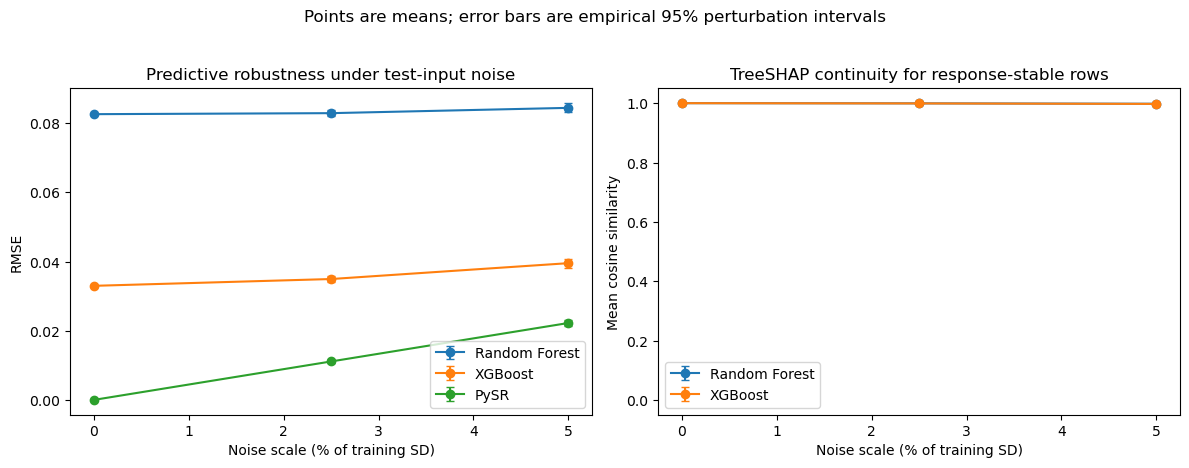

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for model_name in predictions:
    model_noise = noise_results[noise_results["Method"] == model_name]
    rmse = model_noise["RMSE"].to_numpy()
    rmse_interval = np.vstack(
        [
            rmse - model_noise["RMSE 2.5%"].to_numpy(),
            model_noise["RMSE 97.5%"].to_numpy() - rmse,
        ]
    )
    axes[0].errorbar(
        model_noise["Noise (% training SD)"],
        rmse,
        yerr=np.maximum(rmse_interval, 0.0),
        marker="o",
        capsize=3,
        label=model_name,
    )

for model_name in models:
    model_noise = noise_results[noise_results["Method"] == model_name]
    stable_cosine = model_noise[
        "Mean SHAP cosine similarity (response-stable rows)"
    ].to_numpy()
    cosine_interval = np.vstack(
        [
            stable_cosine
            - model_noise["Stable-response SHAP cosine 2.5%"].to_numpy(),
            model_noise["Stable-response SHAP cosine 97.5%"].to_numpy()
            - stable_cosine,
        ]
    )
    axes[1].errorbar(
        model_noise["Noise (% training SD)"],
        stable_cosine,
        yerr=np.maximum(cosine_interval, 0.0),
        marker="o",
        capsize=3,
        label=model_name,
    )

axes[0].set_title("Predictive robustness under test-input noise")
axes[0].set_xlabel("Noise scale (% of training SD)")
axes[0].set_ylabel("RMSE")
axes[0].legend()

axes[1].set_title("TreeSHAP continuity for response-stable rows")
axes[1].set_xlabel("Noise scale (% of training SD)")
axes[1].set_ylabel("Mean cosine similarity")
axes[1].set_ylim(-0.05, 1.05)
axes[1].legend()

fig.suptitle(
    "Points are means; error bars are empirical 95% perturbation intervals",
    y=1.03,
)
plt.tight_layout()
plt.show()


### 4. Compactness snapshot

These are representation-specific descriptions, not directly equivalent scores. For each tree-model test row, features are ordered by absolute SHAP magnitude and counted until they explain at least 90% of that row's total absolute SHAP magnitude; the reported value is the average count.


In [11]:
def feature_counts_for_shap_coverage(values, coverage=0.90):
    absolute_values = np.abs(values)
    counts = []
    for row in absolute_values:
        total = row.sum()
        if total <= np.finfo(float).eps:
            counts.append(0)
            continue
        cumulative = np.cumsum(np.sort(row)[::-1])
        counts.append(
            np.searchsorted(cumulative, coverage * total, side="left") + 1
        )
    return np.asarray(counts)


tree_compactness = {
    model_name: feature_counts_for_shap_coverage(values).mean()
    for model_name, values in clean_shap_values.items()
}

compactness_rows = [
    {
        "Method": model_name,
        "Average features for 90% |SHAP|": average_count,
        "Expression complexity": np.nan,
        "Variables used": np.nan,
    }
    for model_name, average_count in tree_compactness.items()
]
compactness_rows.append(
    {
        "Method": "PySR",
        "Average features for 90% |SHAP|": np.nan,
        "Expression complexity": PYSR_RESULT["complexity"],
        "Variables used": len(pysr_variables),
    }
)
compactness = pd.DataFrame(compactness_rows).set_index("Method")
display(compactness.round(2))


,Average features for 90% |SHAP|,Expression complexity,Variables used
Method,,,
Random Forest,4.68,NaN,NaN
XGBoost,4.52,NaN,NaN
PySR,NaN,17.0,6.0


## Save models and test results

The model files include preprocessing assumptions only implicitly: inputs must contain the six feature columns in the same units and order used here.

In [12]:
if SAVE_ARTIFACTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    artifact_names = {
        "Random Forest": "random_forest_best.joblib",
        "XGBoost": "xgboost_best.joblib",
    }
    for model_name, model in models.items():
        model_path = OUTPUT_DIR / artifact_names[model_name]
        joblib.dump(model, model_path)
        print(f"Saved {model_name}: {model_path}")

    metrics.reset_index().to_csv(OUTPUT_DIR / "metrics.csv", index=False)
    noise_results.to_csv(OUTPUT_DIR / "noise_sensitivity.csv", index=False)
    noise_run_results.to_csv(
        OUTPUT_DIR / "noise_sensitivity_repeats.csv", index=False
    )

    test_results = X_test.copy()
    test_results.insert(0, "source_row_index", X_test.index)
    test_results["actual_target"] = y_test
    for model_name, split_predictions in predictions.items():
        prediction_column = model_name.lower().replace(" ", "_") + "_prediction"
        test_results[prediction_column] = split_predictions["test"]
    test_results.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

    manifest = {
        "data_path": str(DATA_PATH),
        "random_state": RANDOM_STATE,
        "test_size": TEST_SIZE,
        "feature_columns": FEATURE_COLUMNS,
        "rf_params": RF_PARAMS,
        "xgb_params": XGB_PARAMS,
        "pysr_result": PYSR_RESULT,
        "continuity_method": (
            "Paired Gaussian perturbations without clipping; TreeSHAP cosine "
            "similarity reported for response-stable rows"
        ),
        "response_stability_tolerance": float(
            response_stability_tolerance
        ),
        "noise_levels": NOISE_LEVELS,
        "noise_repeats": NOISE_REPEATS,
        "continuity_repeats": CONTINUITY_REPEATS,
        "continuity_sample_size": len(continuity_positions),
        "versions": {
            "scikit_learn": sklearn.__version__,
            "xgboost": xgboost.__version__,
        },
    }
    with (OUTPUT_DIR / "training_manifest.json").open("w", encoding="utf-8") as file:
        json.dump(manifest, file, indent=2)

    print(f"Saved metrics, predictions, and manifest under {OUTPUT_DIR}")

Saved Random Forest: outputs\best_models\random_forest_best.joblib
Saved XGBoost: outputs\best_models\xgboost_best.joblib
Saved metrics, predictions, and manifest under outputs\best_models


## Run predictions on new test rows

Pass a DataFrame containing the six named feature columns. PySR is selected by default because its recovered equation achieved machine-precision test error.

In [13]:
AVAILABLE_MODEL_NAMES = [*models, "PySR"]
DEFAULT_MODEL_FOR_TESTS = "PySR"


def predict_test_rows(rows, model_name=DEFAULT_MODEL_FOR_TESTS):
    if model_name not in AVAILABLE_MODEL_NAMES:
        raise KeyError(
            f"Unknown model {model_name!r}. Available models: {AVAILABLE_MODEL_NAMES}"
        )

    rows = pd.DataFrame(rows).copy()
    missing = [column for column in FEATURE_COLUMNS if column not in rows.columns]
    if missing:
        raise ValueError(f"Missing feature columns: {missing}")
    if not np.isfinite(rows[FEATURE_COLUMNS].to_numpy()).all():
        raise ValueError("Test rows contain missing or non-finite feature values.")

    result = rows[FEATURE_COLUMNS].copy()
    if model_name == "PySR":
        result["prediction"] = predict_pysr(result)
    else:
        result["prediction"] = models[model_name].predict(result)
    return result


example_rows = X_test.head(5)
example_predictions = predict_test_rows(example_rows)
example_predictions["actual_target"] = y_test.loc[example_rows.index].to_numpy()
print(f"Predictions from: {DEFAULT_MODEL_FOR_TESTS}")
display(example_predictions)

Predictions from: PySR


,m2_m1,x2_x1,y1_x1,y2_x1,z1_x1,z2_x1,prediction,actual_target
6252,0.670724,0.267329,0.880048,0.500082,0.912107,0.390914,0.703933,0.703933
4684,1.345673,0.282436,0.863701,0.254927,0.825437,0.375082,1.236463,1.236463
1731,1.009476,0.419658,0.992582,0.405223,0.969301,0.497591,1.116310,1.116310
4742,0.826115,0.462358,0.942306,0.395185,0.942014,0.304459,0.830369,0.830369
4521,0.827069,0.494050,1.143293,0.392742,1.000017,0.459461,0.744094,0.744094


### Notebook conclusion

This table is a compact exploratory summary. `Prediction Change` and noisy RMSE are means across 100 paired perturbation draws on the full test set at a noise scale equal to 5% of each feature's training-set standard deviation. TreeSHAP continuity uses 20 paired non-zero draws on a fixed, seeded 50-row subset, closely matching the body-fat test-set scale, and is summarized only over response-stable rows.


In [14]:
five_percent_noise = (
    noise_results[noise_results["Noise (% training SD)"] == 5.0]
    .set_index("Method")
)
oracle_alignment_lookup = oracle_alignment[
    "Spearman correlation"
].to_dict()

conclusion_rows = []
for model_name in predictions:
    if model_name in models:
        alignment_or_structure = (
            f"Spearman rho = "
            f"{oracle_alignment_lookup[model_name]:.3f}"
        )
        compactness_text = (
            f"{tree_compactness[model_name]:.2f} features "
            f"for 90% |SHAP|"
        )
    else:
        alignment_or_structure = (
            "Full reconstruction"
        )
        compactness_text = (
            f"complexity {PYSR_RESULT['complexity']}; "
            f"{len(pysr_variables)} variables"
        )

    conclusion_rows.append(
        {
            "Method": model_name,
            "Clean R2": clean_performance.loc[model_name, "R2"],
            "Clean RMSE": clean_performance.loc[model_name, "RMSE"],
            "5% Noise RMSE (mean)": five_percent_noise.loc[
                model_name, "RMSE"
            ],
            "5% Noise RMSE 2.5%": five_percent_noise.loc[
                model_name, "RMSE 2.5%"
            ],
            "5% Noise RMSE 97.5%": five_percent_noise.loc[
                model_name, "RMSE 97.5%"
            ],
            "Prediction Change": five_percent_noise.loc[
                model_name, "Mean absolute prediction change"
            ],
            "Stable-response SHAP cosine": five_percent_noise.loc[
                model_name,
                "Mean SHAP cosine similarity (response-stable rows)",
            ],
            "Oracle Alignment/Structure": alignment_or_structure,
            "Compactness": compactness_text,
        }
    )

conclusion = pd.DataFrame(conclusion_rows).set_index("Method")
display(conclusion.round(6))


,Clean R2,Clean RMSE,5% Noise RMSE (mean),5% Noise RMSE 2.5%,5% Noise RMSE 97.5%,Prediction Change,Stable-response SHAP cosine,Oracle Alignment/Structure,Compactness
Method,,,,,,,,,
Random Forest,0.955581,0.082653,0.084478,0.083279,0.085835,0.017378,0.998045,Spearman rho = 0.943,4.68 features for 90% |SHAP|
XGBoost,0.992921,0.032996,0.039548,0.038261,0.040688,0.021643,0.997526,Spearman rho = 0.943,4.52 features for 90% |SHAP|
PySR,1.000000,0.000000,0.022237,0.021293,0.023048,0.016885,NaN,Full reconstruction,complexity 17; 6 variables
